# 02 · PCA as loss minimisation, and the spline framework

Covers sections 1.2–1.3 of the thesis [`lavado2012phd`] (MSc thesis, chapter 2 [`lavado2004msc`]; the Gifi system:
[`gifi1991nonlinear`, `michailidis1998gifi`, `bekker1988relations`]).

The idea of this notebook: **ordinary PCA is the solution of a loss-minimisation problem**, and
qlPCA is obtained from the same problem by *allowing each variable to be transformed* inside a class of spline functions.
Choosing the class (degree $v$, number of interior knots $r$) interpolates between the rigid linear case (PCA) and the
free piecewise-constant case (MCA).

*Contents:* 1. the loss function · 2. PCA minimises it · 3. a spline framework for the variants of PCA ·
4. more flexibility, less loss — and the price · References.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qlpca import QLPCA
from qlpca.datasets import load_st_gender
from qlpca.plots import set_style, BLUE, ORANGE, INK2, GRID

set_style()
X, names, countries = load_st_gender()          # thesis chapter 4 data: 15 EU countries, 11 variables
n, m = X.shape
print(n, "objects,", m, "variables")

15 objects, 11 variables


## 1 · The loss function

Let $H$ ($n\times m$) hold the standardised data, $X$ ($n\times p$) the $p$ retained components (object scores, with
$X'X=nI$) and $a_j$ ($p$-vector) the loadings of variable $j$. PCA keeps the maximum information of the original variables in
the components: the components, weighted by the loadings, should approximate the variables. The thesis writes the loss (1.7)

$$\sigma(X,F)=\frac1n\sum_{j=1}^{m}(Xa_j-f_j)'(Xa_j-f_j),\qquad X'X=nI,$$

where $f_j=\varphi_j(h_j)$ is the *transformed* variable. In PCA $f_j=h_j$ (standardised). In the nonlinear variants of the
Gifi family the optimisation also runs over the admissible transformations $\varphi_j$.
An equivalent form (1.8), the usual one in the Gifi literature, is $\sigma=n^{-1}\sum_j\operatorname{tr}(X-f_ja_j')'(X-f_ja_j')$.

The two forms differ by a constant when $a_j$ is optimal: at $a_j=X'f_j/n$,
$\|Xa_j-f_j\|^2=n(1-\|a_j\|^2)$ while $\|X-f_ja_j'\|^2=n(p-\|a_j\|^2)$, so $\sigma_{(1.8)}-\sigma_{(1.7)}=m(p-1)$.
Both have the same minimiser. The next cell checks this numerically on the fitted PCA.

In [2]:
pca = QLPCA(2, degree=1, n_knots=0).fit(X)       # degree 1, no interior knots: linear transformations
S, F, A = pca.scores_, pca.transformed_, pca.loadings_      # A: m x p, row j = a_j'
p = 2

sigma_17 = sum(np.sum((S @ A[j] - F[:, j]) ** 2) for j in range(m)) / n
sigma_18 = sum(np.sum((S - np.outer(F[:, j], A[j])) ** 2) for j in range(m)) / n
print(f"sigma (1.7) = {sigma_17:.6f}   sigma (1.8) = {sigma_18:.6f}   difference = {sigma_18 - sigma_17:.6f}   m(p-1) = {m * (p - 1)}")
print("a_j = X'f_j / n at the solution:", np.allclose(A, (S.T @ F / n).T))

sigma (1.7) = 4.192512   sigma (1.8) = 15.192512   difference = 11.000000   m(p-1) = 11
a_j = X'f_j / n at the solution: True


## 2 · PCA minimises the loss

With linear transformations, $F$ is the standardised data, the optimal $(X,A)$ comes from the singular value decomposition of $F$
(equivalently the eigen-decomposition of the correlation matrix), and the minimum loss is
$m-\lambda_1-\dots-\lambda_p$, where the $\lambda_s$ are the eigenvalues of the correlation matrix — the *variance accounted for*.
Below, the package's `QLPCA(degree=1, n_knots=0)` — which minimises $\sigma$ by alternating least squares — is compared with the
textbook eigenvalues (thesis Table 4.3).

In [3]:
import json, pathlib
ref = json.load(open(pathlib.Path("..") / "tests" / "reference_values.json", encoding="utf8"))
ev = np.linalg.eigvalsh(np.corrcoef(X.T))[::-1]
thesis = np.array(ref["table_4_3_pca"]["eigenvalues"])
print("eigenvalues of the correlation matrix (computed):", ev.round(3))
print("thesis Table 4.3                                :", thesis)
print("max |difference|:", np.abs(ev - thesis).max().round(4))
print()
print("loss of the ALS solution :", round(pca.loss_, 8))
print("m - (lambda_1 + lambda_2):", round(m - ev[:2].sum(), 8))
print("cumulative % VAF, 2 components:", round(100 * ev[:2].sum() / m, 2), "(thesis 61.89)")

eigenvalues of the correlation matrix (computed): [4.276 2.532 1.878 1.037 0.574 0.387 0.148 0.071 0.055 0.027 0.017]
thesis Table 4.3                                : [4.276 2.531 1.878 1.037 0.574 0.387 0.148 0.071 0.055 0.027 0.017]
max |difference|: 0.0006

loss of the ALS solution : 4.19251215
m - (lambda_1 + lambda_2): 4.19251215
cumulative % VAF, 2 components: 61.89 (thesis 61.89)


(The maximum difference to the thesis table, 0.0006, is rounding in the printed values.)

## 3 · A spline framework for the variants of PCA

Take $f_j=\varphi_j(h_j)=\sum_{i=1}^{w}\alpha_i I_i^{[v]}(h_j)$, a spline of degree $v$ with $r$ interior knots generated by
$w=v+r$ I-splines (notebook 01, eq. 1.10 of the thesis). Special cases:

| class of $\varphi_j$ | degree | knots | result |
|---|---|---|---|
| linear | 1 | none | **ordinary PCA** (optimal $f_j$ is the standardised variable) |
| piecewise constant | 0 | maximal (one level per category) | **MCA / HOMALS** (equivalence shown by Bekker & De Leeuw [`bekker1988relations`]) |
| piecewise linear | 1 | $r=1,2,3$ | **qlPCA** — flexible but still interpretable |

Both extremes use the least amount of freedom (linear) or the most (piecewise constant). The intermediate
cases trade fit against respect for the nature of the variable: the more and the higher-order knots, the more the
transformation departs from the original scale.

Two further choices belong to the framework [`gifi1991nonlinear`, `meulman2004principal`]:

* **Single vs Multiple treatment.** *Multiple*: each variable gets $p$ different quantifications, one per dimension (HOMALS).
  *Single*: one transformation $f_j$ per variable, so the $n\times p$ matrix $M_j=f_ja_j'$ has rank one (CATPCA for numeric/spline
  variables, qlPCA). qlPCA uses Single for all variables.
* **Order restrictions.** Ordinal variables call for non-decreasing $f_j$: `QLPCA(monotone=True)` (notebook 01 §6).

The figure shows what the classes mean on real data: the optimal transformation of two variables of the chapter 4 data set
for $r=0$ (linear), $r=1$ and $r=2$ interior knots.

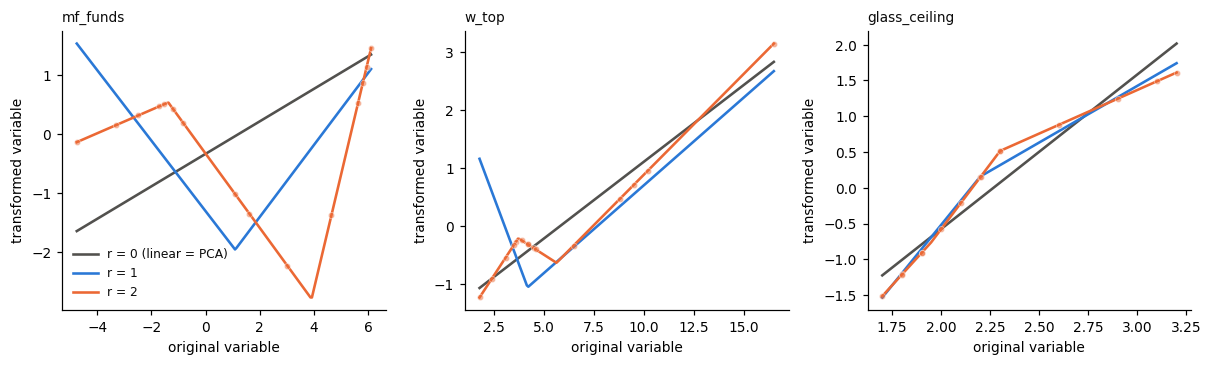

In [4]:
fits = {r: QLPCA(2, degree=1, n_knots=r, random_state=0).fit(X) for r in (0, 1, 2)}
cols = {0: INK2, 1: BLUE, 2: ORANGE}
labels = {0: "r = 0 (linear = PCA)", 1: "r = 1", 2: "r = 2"}
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, j in zip(axes, [names.index(v) for v in ("mf_funds", "w_top", "glass_ceiling")]):
    for r, mdl in fits.items():
        xg, fg = mdl.variable_transformation(j)
        ax.plot(xg, fg, color=cols[r], lw=1.7, label=labels[r])
    ax.scatter(X[:, j], fits[2].transformed_[:, j], s=16, color=ORANGE, alpha=0.5, edgecolor="white", linewidth=0.5, zorder=3)
    ax.set_title(names[j], loc="left", fontsize=9)
    ax.set_xlabel("original variable"); ax.set_ylabel("transformed variable")
    for s in ("top", "right"): ax.spines[s].set_visible(False)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

The linear case is a straight line (the standardised variable). With one or two knots the curve bends where the
relation with the rest of the variables changes; points are the observations transformed with $r=2$. Note that the sign
of a transformation is not identified when it is not monotone — see notebook 04 for the sign convention used here.

## 4 · More flexibility, less loss — and the price

Because each class contains the previous ones in this sequence, $\sigma$ can only decrease as knots are added. The table
shows the variance accounted for by two components, together with the ratio of observations to basis functions
$n/w$. The thesis warns about **over-parametrisation** [`winsberg1983monotone`]: each variable's regression has $w=v+r$
predictors, and "at least 5, preferably 10, observations per predictor" is the usual rule of thumb. With $n=15$ that
allows at most $r=2$ for linear splines.

Caution when reading the percentages: the VAF of a nonlinear variant refers to the *transformed* matrix, not to the original data,
so it cannot be compared directly with the PCA percentage (thesis pp. 60–61, [`lebart2006validation`, `asan2011biplots`]).

In [5]:
print(" r  w=v+r   n/w   VAF 2 components (%)   loss")
for r in range(0, 5):
    mdl = QLPCA(2, degree=1, n_knots=r, random_state=0).fit(X)
    w = 1 + r
    flag = "" if n / w >= 5 else "   <- fewer than 5 observations per basis function"
    print(f"{r:2d}  {w:5d}  {n / w:5.1f}   {100 * mdl.eigenvalues_.sum() / m:18.2f}   {mdl.loss_:6.3f}{flag}")
print("\nthesis: PCA 61.89 (Table 4.3), qlPCA r=1 68.90, r=2 76.33 (Table 4.5)")

 r  w=v+r   n/w   VAF 2 components (%)   loss
 0      1   15.0                61.89    4.193


 1      2    7.5                68.90    3.421


 2      3    5.0                76.33    2.604


 3      4    3.8                78.38    2.378   <- fewer than 5 observations per basis function


 4      5    3.0                84.65    1.688   <- fewer than 5 observations per basis function

thesis: PCA 61.89 (Table 4.3), qlPCA r=1 68.90, r=2 76.33 (Table 4.5)


The loss falls monotonically with $r$, but beyond $r=2$ the gain is partly an artefact: with 15 objects and 4–5 basis functions
per variable the transformations start to interpolate the data.

## References

* `lavado2012phd` — N. Lavado, PhD thesis, ISCTE-IUL, 2012. §1.2 (loss function), §1.3 (spline framework), Table 4.3, Table 4.5.
* `lavado2004msc` — N. Lavado, MSc thesis, ISEGI-UNL, 2004.
* `gifi1991nonlinear` — A. Gifi, *Nonlinear Multivariate Analysis*, Wiley, 1991.
* `michailidis1998gifi` — G. Michailidis & J. de Leeuw, The Gifi system of descriptive multivariate analysis, *Statistical Science* 13, 1998.
* `bekker1988relations` — P. Bekker & J. de Leeuw, Relations between variants of non-linear principal components analysis, in *Component and Correspondence Analysis*, Wiley, 1988.
* `meulman2004principal` — J. Meulman, A. van der Kooij & W. Heiser, Principal components analysis with nonlinear optimal scaling transformations for ordinal and nominal data, in *Sage Handbook of Quantitative Methodology*, 2004.
* `winsberg1983monotone` — S. Winsberg & J. Ramsay, *Psychometrika* 48, 1983.
* `lebart2006validation`, `asan2011biplots` — on the interpretation of percentages of variance in nonlinear variants.